<a href="https://colab.research.google.com/github/fdibie87/mnist-mlflow-deep-learning/blob/main/1_MNIST_MLflow_Experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
!pip install -q mlflow dagshub

In [32]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import mlflow
import mlflow.tensorflow
import dagshub

import pandas as pd
import numpy as np


In [33]:
DAGSHUB_USERNAME = 'fdibie87'
REPO_NAME = 'mnist-mlflow-deep-learning'

dagshub.init(
    repo_owner=DAGSHUB_USERNAME,
    repo_name=REPO_NAME,
    mlflow=True)

print('MLflow Tracking URI:')
print(mlflow.get_tracking_uri())

Initialized MLflow to track repo "fdibie87/mnist-mlflow-deep-learning"

Repository fdibie87/mnist-mlflow-deep-learning initialized!

MLflow Tracking URI:
https://dagshub.com/fdibie87/mnist-mlflow-deep-learning.mlflow


In [34]:
EXPERIMENT_NAME = 'MNIST Deep Learning Experiments'
mlflow.set_experiment(EXPERIMENT_NAME)


<Experiment: artifact_location='mlflow-artifacts:/229c3b8686fe4cb4ba0c8c52f3711570', creation_time=1792633537414, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792633537414, lifecycle_stage='active', name='MNIST Deep Learning Experiments', tags={}, trace_location=None, workspace='default'>

In [35]:
mlflow.tensorflow.autolog(
    log_models=True,
    log_model_signatures=True)


In [36]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print('Training images:', X_train.shape)
print('Training labels:', y_train.shape)
print('Testing images:', X_test.shape)
print('Testing labels:', y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


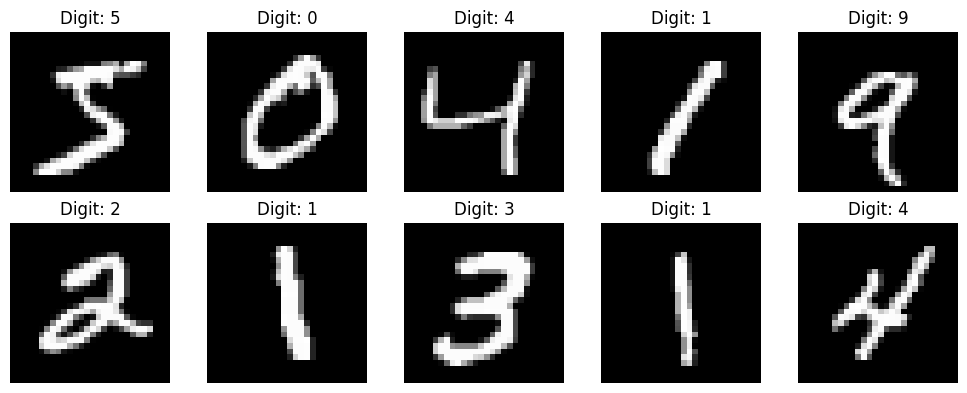

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f'Digit: {y_train[i]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [38]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print('Minimum pixel value:', X_train.min())
print('Maximum pixel value:', X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [39]:
baseline_model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')])

baseline_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

baseline_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
# Start MLflow tracking
with mlflow.start_run(run_name='Baseline_128_Adam_BS64_E50'):

    mlflow.log_param('number_of_hidden_layers', 1)
    mlflow.log_param('nodes_in_hidden_layers', '128')
    mlflow.log_param('optimizer', 'adam')
    mlflow.log_param('batch_size_custom', 64)
    mlflow.log_param('epochs_custom', 50)

    baseline_history = baseline_model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=50,
        batch_size=64,
        verbose=1
    )

    print('\nBASELINE RESULTS')
    print('Training Accuracy:', baseline_history.history['accuracy'][-1])
    print('Validation Accuracy:', baseline_history.history['val_accuracy'][-1])
    print('Training Loss:', baseline_history.history['loss'][-1])
    print('Validation Loss:', baseline_history.history['val_loss'][-1])

Epoch 1/50
746/750 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8459 - loss: 0.5573

750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9066 - loss: 0.3320 - val_accuracy: 0.9494 - val_loss: 0.1816
Epoch 2/50
743/750 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9545 - loss: 0.1626

750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9557 - loss: 0.1548 - val_accuracy: 0.9622 - val_loss: 0.1343
Epoch 3/50
742/750 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9676 - loss: 0.1125

750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9690 - loss: 0.1070 - val_accuracy: 0.9672 - val_loss: 0.1132
Epoch 4/50
749/750 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9761 - loss: 0.0822

750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9762 - loss: 0.0814 - val_accuracy: 0.9701 - val_loss: 0.1031
Epoch 5/50
749/750 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9819 - loss: 0.0647

...

750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9855 - loss: 0.0510 - val_accuracy: 0.9736 - val_loss: 0.0896
Epoch 7/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9884 - loss: 0.0405 - val_accuracy: 0.9727 - val_loss: 0.0925
Epoch 8/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9906 - loss: 0.0331 - val_accuracy: 0.9740 - val_loss: 0.0910
Epoch 9/50
742/750 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9928 - loss: 0.0267

750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9929 - loss: 0.0261 - val_accuracy: 0.9753 - val_loss: 0.0846
Epoch 10/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9944 - loss: 0.0212 - val_accuracy: 0.9732 - val_loss: 0.0962
Epoch 11/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9958 - loss: 0.0172 - val_accuracy: 0.9728 - val_loss: 0.0995
Epoch 12/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9966 - loss: 0.0148 - val_accuracy: 0.9759 - val_loss: 0.0882
Epoch 13/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9976 - loss: 0.0112 - val_accuracy: 0.9752 - val_loss: 0.0899
Epoch 14/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9978 - loss: 0.0100 - val_accuracy: 0.9751 - val_loss: 0.0954
Epoch 15/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9982 - loss: 0.0083 - val_accuracy: 0.9740 - val_loss: 0.1069
Epoch 16/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9984 - loss: 0.0076 - val_accuracy: 0.9

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


2026/10/22 01:50:39 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/22 01:50:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during tensorflow autologging: BAD_REQUEST: Response: {'error_code': 'BAD_REQUEST'}



BASELINE RESULTS
Training Accuracy: 1.0
Validation Accuracy: 0.9791666865348816
Training Loss: 0.00010669438779586926
Validation Loss: 0.1294964849948883
🏃 View run Baseline_128_Adam_BS64_E50 at: https://dagshub.com/fdibie87/mnist-mlflow-deep-learning.mlflow/#/experiments/1/runs/fcef25b7c7294b4a8067cf4c5d1fad01
🧪 View experiment at: https://dagshub.com/fdibie87/mnist-mlflow-deep-learning.mlflow/#/experiments/1


In [41]:
def run_experiment(run_name, hidden_nodes, optimizer, batch_size, epochs):
    model = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten()])

    for nodes in hidden_nodes:
        model.add(layers.Dense(nodes, activation='relu'))

    model.add(layers.Dense(10, activation='softmax'))

    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])

    with mlflow.start_run(run_name=run_name):
        # Log hyperparameters
        mlflow.log_param('number_of_hidden_layers', len(hidden_nodes))
        mlflow.log_param('nodes_in_hidden_layers', '-'.join(map(str, hidden_nodes)))
        mlflow.log_param('optimizer', optimizer)
        mlflow.log_param('batch_size_custom', batch_size)
        mlflow.log_param('epochs_custom', epochs)

        history = model.fit(
            X_train,
            y_train,
            validation_split=0.2,
            epochs=epochs,
            batch_size=batch_size,
            verbose=1)

        print(f'\nRESULTS: {run_name}')
        print('Training Accuracy:', history.history['accuracy'][-1])
        print('Validation Accuracy:', history.history['val_accuracy'][-1])
        print('Training Loss:', history.history['loss'][-1])
        print('Validation Loss:', history.history['val_loss'][-1])

    return history

In [42]:
history_exp2 = run_experiment(
    run_name='Exp2_256_Adam_BS64_E50',
    hidden_nodes=[256],
    optimizer='adam',
    batch_size=64,
    epochs=50)

Epoch 1/50
745/750 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8661 - loss: 0.4824

750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9191 - loss: 0.2865 - val_accuracy: 0.9573 - val_loss: 0.1497
Epoch 2/50
745/750 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9615 - loss: 0.1326

750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9646 - loss: 0.1211 - val_accuracy: 0.9690 - val_loss: 0.1076
Epoch 3/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9762 - loss: 0.0840

750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.9767 - loss: 0.0802 - val_accuracy: 0.9715 - val_loss: 0.0936
Epoch 4/50
743/750 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9836 - loss: 0.0563

750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9826 - loss: 0.0592 - val_accuracy: 0.9735 - val_loss: 0.0844
Epoch 5/50
742/750 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9881 - loss: 0.0405

...

750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9904 - loss: 0.0335 - val_accuracy: 0.9772 - val_loss: 0.0787
Epoch 7/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9930 - loss: 0.0250 - val_accuracy: 0.9770 - val_loss: 0.0787
Epoch 8/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9946 - loss: 0.0192 - val_accuracy: 0.9736 - val_loss: 0.0882
Epoch 9/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9957 - loss: 0.0164 - val_accuracy: 0.9770 - val_loss: 0.0856
Epoch 10/50
743/750 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9968 - loss: 0.0124

750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9966 - loss: 0.0128 - val_accuracy: 0.9788 - val_loss: 0.0787
Epoch 11/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9978 - loss: 0.0091 - val_accuracy: 0.9782 - val_loss: 0.0849
Epoch 12/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9970 - loss: 0.0100 - val_accuracy: 0.9768 - val_loss: 0.0931
Epoch 13/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9979 - loss: 0.0080 - val_accuracy: 0.9764 - val_loss: 0.0926
Epoch 14/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9988 - loss: 0.0058 - val_accuracy: 0.9793 - val_loss: 0.0868
Epoch 15/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9991 - loss: 0.0044 - val_accuracy: 0.9784 - val_loss: 0.0987
Epoch 16/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9987 - loss: 0.0052 - val_accuracy: 0.9745 - val_loss: 0.1041
Epoch 17/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9976 - loss: 0.0084 - val_accuracy: 0.9787

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step


2026/10/22 01:56:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/22 01:56:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during tensorflow autologging: BAD_REQUEST: Response: {'error_code': 'BAD_REQUEST'}



RESULTS: Exp2_256_Adam_BS64_E50
Training Accuracy: 1.0
Validation Accuracy: 0.9807500243186951
Training Loss: 1.409787728334777e-05
Validation Loss: 0.12370122969150543
🏃 View run Exp2_256_Adam_BS64_E50 at: https://dagshub.com/fdibie87/mnist-mlflow-deep-learning.mlflow/#/experiments/1/runs/b0118b3ad44d44f6a8990f81ca4af325
🧪 View experiment at: https://dagshub.com/fdibie87/mnist-mlflow-deep-learning.mlflow/#/experiments/1


In [43]:
history_exp3 = run_experiment(
    run_name='Exp3_128x64_Adam_BS64_E50',
    hidden_nodes=[128, 64],
    optimizer='adam',
    batch_size=64,
    epochs=50)

Epoch 1/50
747/750 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8496 - loss: 0.5392

750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9144 - loss: 0.3000 - val_accuracy: 0.9542 - val_loss: 0.1549
Epoch 2/50
747/750 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9608 - loss: 0.1294

750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9620 - loss: 0.1262 - val_accuracy: 0.9657 - val_loss: 0.1199
Epoch 3/50
740/750 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9729 - loss: 0.0899

750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9740 - loss: 0.0862 - val_accuracy: 0.9692 - val_loss: 0.1050
Epoch 4/50
739/750 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9821 - loss: 0.0607

750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9804 - loss: 0.0644 - val_accuracy: 0.9725 - val_loss: 0.0966
Epoch 5/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9846 - loss: 0.0502 - val_accuracy: 0.9671 - val_loss: 0.1139
Epoch 6/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9877 - loss: 0.0401 - val_accuracy: 0.9732 - val_loss: 0.0993
Epoch 7/50
742/750 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9908 - loss: 0.0301

750/750 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.9896 - loss: 0.0324 - val_accuracy: 0.9741 - val_loss: 0.0939
Epoch 8/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9917 - loss: 0.0253 - val_accuracy: 0.9760 - val_loss: 0.0946
Epoch 9/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9921 - loss: 0.0238 - val_accuracy: 0.9740 - val_loss: 0.0950
Epoch 10/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9947 - loss: 0.0175 - val_accuracy: 0.9736 - val_loss: 0.1047
Epoch 11/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9948 - loss: 0.0160 - val_accuracy: 0.9732 - val_loss: 0.1137
Epoch 12/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9953 - loss: 0.0144 - val_accuracy: 0.9740 - val_loss: 0.1144
Epoch 13/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9954 - loss: 0.0146 - val_accuracy: 0.9671 - val_loss: 0.1485
Epoch 14/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9960 - loss: 0.0127 - val_accuracy: 0.9768

2026/10/22 02:00:45 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/22 02:00:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during tensorflow autologging: BAD_REQUEST: Response: {'error_code': 'BAD_REQUEST'}



RESULTS: Exp3_128x64_Adam_BS64_E50
Training Accuracy: 0.9994166493415833
Validation Accuracy: 0.9761666655540466
Training Loss: 0.00200721831060946
Validation Loss: 0.19642283022403717
🏃 View run Exp3_128x64_Adam_BS64_E50 at: https://dagshub.com/fdibie87/mnist-mlflow-deep-learning.mlflow/#/experiments/1/runs/97eca99df9f749f5972f54beb4497aa5
🧪 View experiment at: https://dagshub.com/fdibie87/mnist-mlflow-deep-learning.mlflow/#/experiments/1


In [44]:
history_exp4 = run_experiment(
    run_name='Exp4_256x128_RMSprop_BS128_E30',
    hidden_nodes=[256, 128],
    optimizer='rmsprop',
    batch_size=128,
    epochs=30)

Epoch 1/30
372/375 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8408 - loss: 0.5316

375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.9101 - loss: 0.3028 - val_accuracy: 0.9504 - val_loss: 0.1733
Epoch 2/30
368/375 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9599 - loss: 0.1327

375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.9644 - loss: 0.1176 - val_accuracy: 0.9625 - val_loss: 0.1234
Epoch 3/30
373/375 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9767 - loss: 0.0819

375/375 ━━━━━━━━━━━━━━━━━━━━ 16s 42ms/step - accuracy: 0.9774 - loss: 0.0759 - val_accuracy: 0.9721 - val_loss: 0.0934
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9827 - loss: 0.0553

375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9825 - loss: 0.0548 - val_accuracy: 0.9758 - val_loss: 0.0825
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9884 - loss: 0.0392 - val_accuracy: 0.9763 - val_loss: 0.0839
Epoch 6/30
373/375 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9911 - loss: 0.0275

375/375 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step - accuracy: 0.9902 - loss: 0.0307 - val_accuracy: 0.9774 - val_loss: 0.0822
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9927 - loss: 0.0236 - val_accuracy: 0.9780 - val_loss: 0.0828
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9942 - loss: 0.0186 - val_accuracy: 0.9754 - val_loss: 0.1058
Epoch 9/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9958 - loss: 0.0137 - val_accuracy: 0.9796 - val_loss: 0.0929
Epoch 10/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9964 - loss: 0.0110 - val_accuracy: 0.9745 - val_loss: 0.1132
Epoch 11/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9974 - loss: 0.0085 - val_accuracy: 0.9789 - val_loss: 0.1029
Epoch 12/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9978 - loss: 0.0064 - val_accuracy: 0.9784 - val_loss: 0.1033
Epoch 13/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9983 - loss: 0.0056 - val_accuracy: 0.978

2026/10/22 02:03:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



RESULTS: Exp4_256x128_RMSprop_BS128_E30
Training Accuracy: 1.0
Validation Accuracy: 0.9824166893959045
Training Loss: 1.1457005712145474e-05
Validation Loss: 0.1227482482790947
🏃 View run Exp4_256x128_RMSprop_BS128_E30 at: https://dagshub.com/fdibie87/mnist-mlflow-deep-learning.mlflow/#/experiments/1/runs/76b9fd5c9c8b4dc4aadaefe7c31ad1fe
🧪 View experiment at: https://dagshub.com/fdibie87/mnist-mlflow-deep-learning.mlflow/#/experiments/1


In [45]:
runs = mlflow.search_runs(
    experiment_names=['MNIST Deep Learning Experiments'])
columns = [
    'tags.mlflow.runName',
    'params.number_of_hidden_layers',
    'params.nodes_in_hidden_layers',
    'params.optimizer',
    'params.batch_size_custom',
    'params.epochs_custom',
    'metrics.accuracy',
    'metrics.val_accuracy',
    'metrics.loss',
    'metrics.val_loss']

results = runs[columns].copy()

results.columns = [
    'Run Name',
    'Hidden Layers',
    'Hidden Neurons',
    'Optimizer',
    'Batch Size',
    'Epochs',
    'Training Accuracy',
    'Validation Accuracy',
    'Training Loss',
    'Validation Loss']

display(results)

,Run Name,Hidden Layers,Hidden Neurons,Optimizer,Batch Size,Epochs,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss
0,Exp4_256x128_RMSprop_BS128_E30,2,256-128,rmsprop,128,30,1.000000,0.982417,0.000011,0.122748
1,Exp3_128x64_Adam_BS64_E50,2,128-64,adam,64,50,0.999417,0.976167,0.002007,0.196423
2,Exp2_256_Adam_BS64_E50,1,256,adam,64,50,1.000000,0.980750,0.000014,0.123701
3,Baseline_128_Adam_BS64_E50,1,128,adam,64,50,1.000000,0.979167,0.000107,0.129496


In [46]:
best_model = results.sort_values(
    by=['Validation Accuracy', 'Validation Loss'],
    ascending=[False, True]).iloc[0]

print('BEST-PERFORMING MODEL')
print(best_model)

BEST-PERFORMING MODEL
Run Name               Exp4_256x128_RMSprop_BS128_E30
Hidden Layers                                       2
Hidden Neurons                                256-128
Optimizer                                     rmsprop
Batch Size                                        128
Epochs                                             30
Training Accuracy                                 1.0
Validation Accuracy                          0.982417
Training Loss                                0.000011
Validation Loss                              0.122748
Name: 0, dtype: object


In [47]:
results.to_csv('MNIST_Experiment_Comparison.csv', index=False)

print('Comparison table saved successfully!')

Comparison table saved successfully!


In [48]:
best_model = results.sort_values(
    by=['Validation Accuracy', 'Validation Loss'],
    ascending=[False, True]
).iloc[0]

print('BEST-PERFORMING MODEL')
print(best_model)

BEST-PERFORMING MODEL
Run Name               Exp4_256x128_RMSprop_BS128_E30
Hidden Layers                                       2
Hidden Neurons                                256-128
Optimizer                                     rmsprop
Batch Size                                        128
Epochs                                             30
Training Accuracy                                 1.0
Validation Accuracy                          0.982417
Training Loss                                0.000011
Validation Loss                              0.122748
Name: 0, dtype: object
